# 03 · Visualização — um gráfico por cargo + PCA

**Entrada:** `data/processed/` (CSVs do ETL e tabelas da análise) · **Saída:** `reports/figures/`.

| Figura | Arquivo |
|---|---|
| Presidente | `grafico_presidente.png` |
| Senador | `grafico_senador.png` |
| Deputado Federal | `grafico_deputado_federal.png` |
| Deputado Estadual | `grafico_deputado_estadual.png` |
| PCA (PC1 × PC2 + variância explicada) | `pca_pc1_pc2.png` |
| Correlação de Spearman (complementar) | `spearman_presidente_heatmap.png` |

Para os cargos majoritários o gráfico mostra o resultado; para os proporcionais, a *distribuição* de votos por candidato,
que decide entre média e mediana (regra de ouro da aula: olhe os dados antes de escolher a medida).

## 0. Configuração e leitura dos dados

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

# --- Pastas do repositório: os notebooks ficam em notebooks/, o resto é irmão dessa pasta ---
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"              # JSONs originais do TSE (não versionado, ver .gitignore)
PROC = ROOT / "data" / "processed"       # CSVs gerados pelo ETL e pelas análises (versionado)
FIG = ROOT / "reports" / "figures"       # gráficos
REP = ROOT / "reports"                   # textos entregáveis
for d in (RAW, PROC, FIG, REP):
    d.mkdir(parents=True, exist_ok=True)

COR_REGIAO = {"Norte": "#009E73", "Nordeste": "#E69F00", "Centro-Oeste": "#CC79A7",
              "Sudeste": "#0072B2", "Sul": "#D55E00"}   # paleta Okabe-Ito (daltonismo)
AZUL, CINZA, LARANJA = "#0072B2", "#8A8F98", "#D55E00"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})

def fmt_int(n):
    """Número inteiro no padrão brasileiro: 1.234.567."""
    return f"{n:,.0f}".replace(",", ".")


def fmt_dec(x, casas=1):
    """Decimal no padrão brasileiro: 1.234,5."""
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

ARQUIVOS = {"presidente": "presidente_1t.csv", "senador": "senador_1t.csv",
            "deputado_federal": "deputado_federal_1t.csv", "deputado_estadual": "deputado_estadual_1t.csv"}
df = pd.concat([pd.read_csv(PROC / nome) for nome in ARQUIVOS.values()], ignore_index=True)
dfv = df[df["situacao_candidatura"].eq("Válido")]     # base das análises: votos válidos (sem "Anulado sub judice")
print(f"{len(df)} linhas | {df['cargo'].nunique()} cargos")
df.groupby("cargo")["uf"].nunique().rename("unidades").to_frame().T


# Rodapé com a fonte e o período em que o TSE gerou os arquivos (lido de metadados_tse.csv)
meta = pd.read_csv(PROC / "metadados_tse.csv", parse_dates=["tse_gerado_em"])
GERADO = meta["tse_gerado_em"].dt.strftime("%d/%m").agg(["min", "max"])
FONTE_TXT = (f"Fonte: TSE (resultados.tse.jus.br), 1º turno 04/10/2026; arquivos gerados em {GERADO['min']} a {GERADO['max']}/2026; "
             "RO (deputados) sem totalização final no arquivo.")


def rodape(fig):
    fig.text(0.01, 0.005, FONTE_TXT, fontsize=7.5, color=CINZA, ha="left", va="bottom")

18998 linhas | 4 cargos


## 1. Presidente (Brasil)

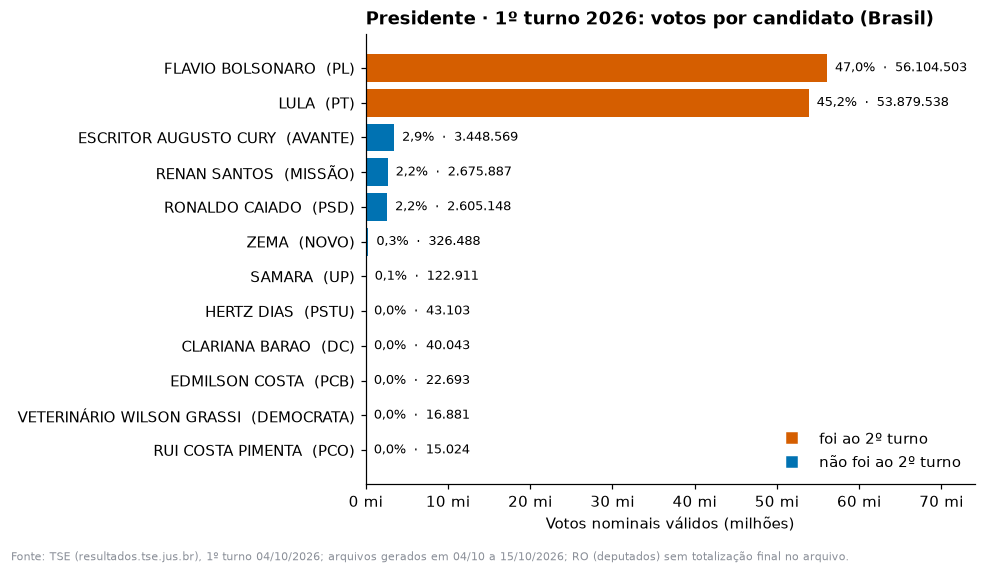

In [2]:
p = dfv[(dfv["cargo"] == "presidente") & (dfv["uf"] == "BR")].sort_values("votos")
fig, ax = plt.subplots(figsize=(9, 5.2))
cores = [LARANJA if r == "2º turno" else AZUL for r in p["resultado"]]
ax.barh(p["candidato"] + "  (" + p["partido"] + ")", p["votos"], color=cores)
for y, (v, pc) in enumerate(zip(p["votos"], p["pct_validos"])):
    ax.text(v, y, f"  {fmt_dec(pc)}%  ·  {fmt_int(v)}", va="center", fontsize=8.5)
ax.set_xlim(0, p["votos"].max() * 1.32)
ax.xaxis.set_major_formatter(lambda x, _: f"{fmt_int(x / 1e6)} mi")
ax.set_xlabel("Votos nominais válidos (milhões)")
ax.set_title("Presidente · 1º turno 2026: votos por candidato (Brasil)", loc="left")
ax.legend(handles=[Line2D([], [], marker="s", ls="", color=LARANJA, label="foi ao 2º turno"),
                   Line2D([], [], marker="s", ls="", color=AZUL, label="não foi ao 2º turno")],
          loc="lower right", frameon=False)
fig.tight_layout(rect=(0, 0.03, 1, 1)); rodape(fig)
fig.savefig(FIG / "grafico_presidente.png"); plt.show()

## 2. Senador — os 15 candidatos mais votados do país

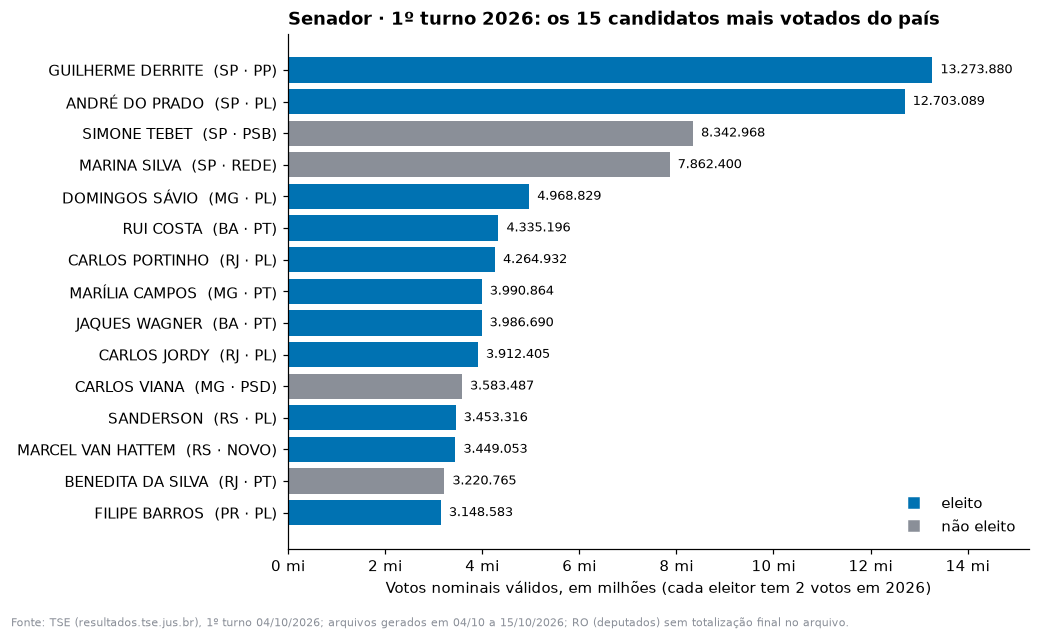

In [3]:
s = dfv[dfv["cargo"] == "senador"].nlargest(15, "votos").sort_values("votos")
eleito = s["resultado"].eq("Eleito")
fig, ax = plt.subplots(figsize=(9.5, 5.8))
ax.barh(s["candidato"] + "  (" + s["uf"] + " · " + s["partido"] + ")", s["votos"],
        color=np.where(eleito, AZUL, CINZA))
for y, v in enumerate(s["votos"]):
    ax.text(v, y, "  " + fmt_int(v), va="center", fontsize=8.5)
ax.set_xlim(0, s["votos"].max() * 1.15)
ax.xaxis.set_major_formatter(lambda x, _: f"{fmt_int(x / 1e6)} mi")
ax.set_xlabel("Votos nominais válidos, em milhões (cada eleitor tem 2 votos em 2026)")
ax.set_title("Senador · 1º turno 2026: os 15 candidatos mais votados do país", loc="left")
ax.legend(handles=[Line2D([], [], marker="s", ls="", color=AZUL, label="eleito"),
                   Line2D([], [], marker="s", ls="", color=CINZA, label="não eleito")],
          loc="lower right", frameon=False)
fig.tight_layout(rect=(0, 0.03, 1, 1)); rodape(fig)
fig.savefig(FIG / "grafico_senador.png"); plt.show()

## 3. Deputado Federal e Deputado Estadual — distribuição dos votos por candidato

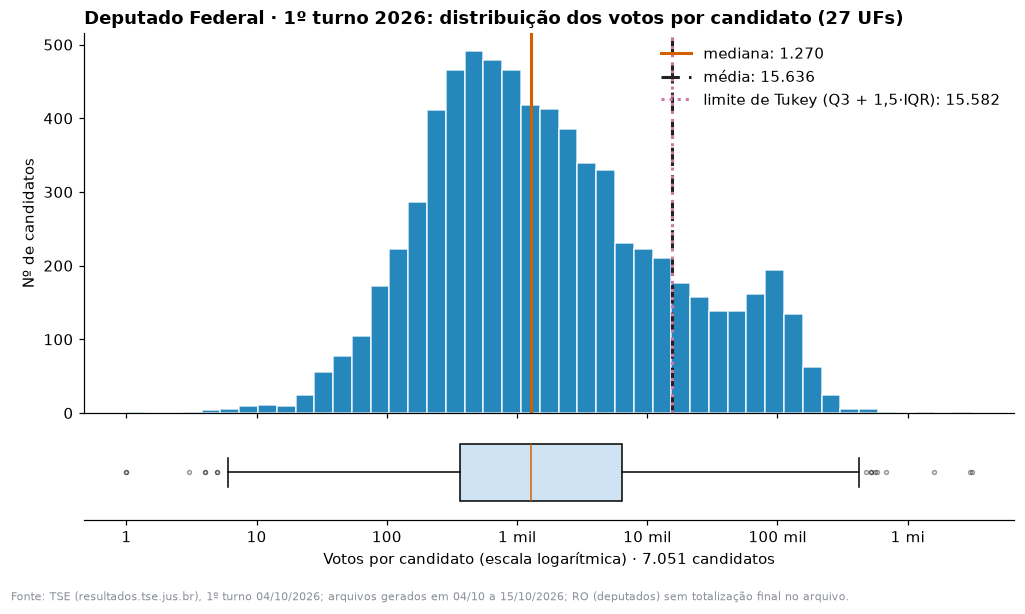

In [4]:
def limites_tukey(x):
    q1, q3 = np.percentile(x, [25, 75])
    return q1, q3, q3 - q1, q3 + 1.5 * (q3 - q1)


def grafico_proporcional(cargo, titulo, arquivo):
    """Histograma (escala log) + boxplot dos votos por candidato, com média, mediana e limite de Tukey."""
    x = dfv.loc[dfv["cargo"] == cargo, "votos"]
    x_pos = x[x > 0]                                          # log de 0 não existe
    q1, q3, iqr, lim = limites_tukey(x)
    fig, (ax, axb) = plt.subplots(2, 1, figsize=(9.5, 5.6), sharex=True,
                                  gridspec_kw={"height_ratios": [4, 1], "hspace": 0.05})
    ax.hist(np.log10(x_pos), bins=45, color=AZUL, alpha=.85, edgecolor="white")
    for valor, rot, cor, ls in [(x.median(), "mediana", LARANJA, "-"), (x.mean(), "média", "#222222", (0, (6, 3))),
                                (lim, "limite de Tukey (Q3 + 1,5·IQR)", "#CC79A7", ":")]:
        ax.axvline(np.log10(valor), color=cor, ls=ls, lw=2, label=f"{rot}: {fmt_int(valor)}")
    ax.set_ylabel("Nº de candidatos")
    ax.set_title(titulo, loc="left")
    ax.legend(frameon=False, loc="upper right")
    axb.boxplot(np.log10(x_pos), orientation="horizontal", widths=.6, flierprops={"markersize": 2.5, "alpha": .4},
                patch_artist=True, boxprops={"facecolor": "#cfe3f2"}, medianprops={"color": LARANJA})
    axb.set_yticks([])
    axb.set_xticks(np.arange(0, 7), ["1", "10", "100", "1 mil", "10 mil", "100 mil", "1 mi"])
    n0 = len(x) - len(x_pos)
    axb.set_xlabel(f"Votos por candidato (escala logarítmica) · {fmt_int(len(x))} candidatos"
                   + (f" ({n0} com 0 voto não aparecem)" if n0 else ""))
    axb.spines["left"].set_visible(False)
    fig.subplots_adjust(left=0.08, right=0.97, top=0.93, bottom=0.14); rodape(fig)
    fig.savefig(FIG / arquivo); plt.show()


grafico_proporcional("deputado_federal", "Deputado Federal · 1º turno 2026: distribuição dos votos por candidato (27 UFs)",
                     "grafico_deputado_federal.png")

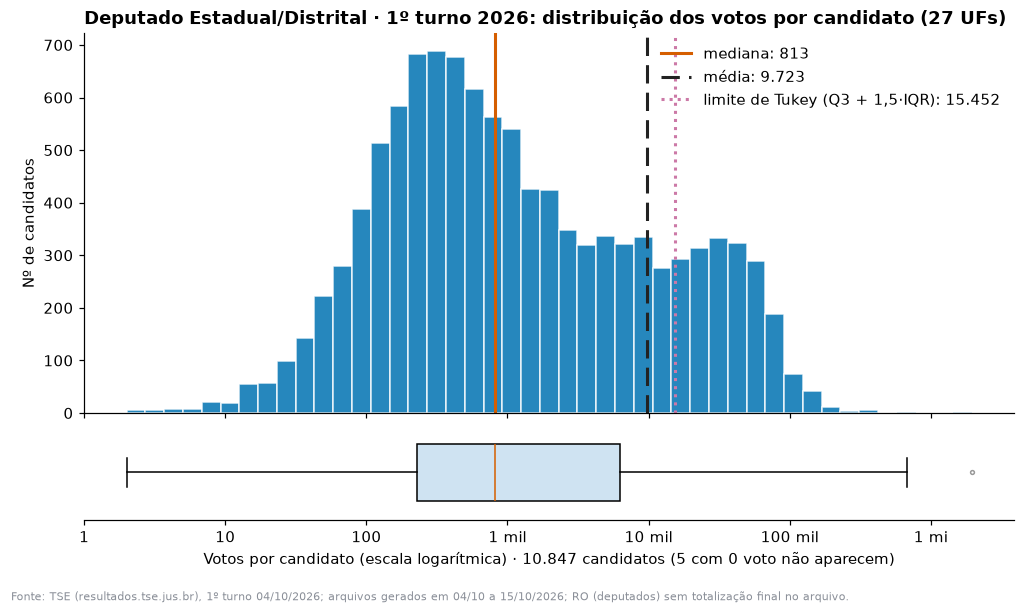

In [5]:
grafico_proporcional("deputado_estadual", "Deputado Estadual/Distrital · 1º turno 2026: distribuição dos votos por candidato (27 UFs)",
                     "grafico_deputado_estadual.png")

## 4. PCA — perfil de votação para presidente nas 27 UFs

Lê as tabelas geradas no `02_Analise.ipynb` (`pca_scores_ufs.csv`, `pca_loadings.csv`, `pca_variancia.csv`).
Os **pontos** são as UFs (posição = scores); as **setas** são os candidatos (direção = loadings, ampliadas só para caber no gráfico).

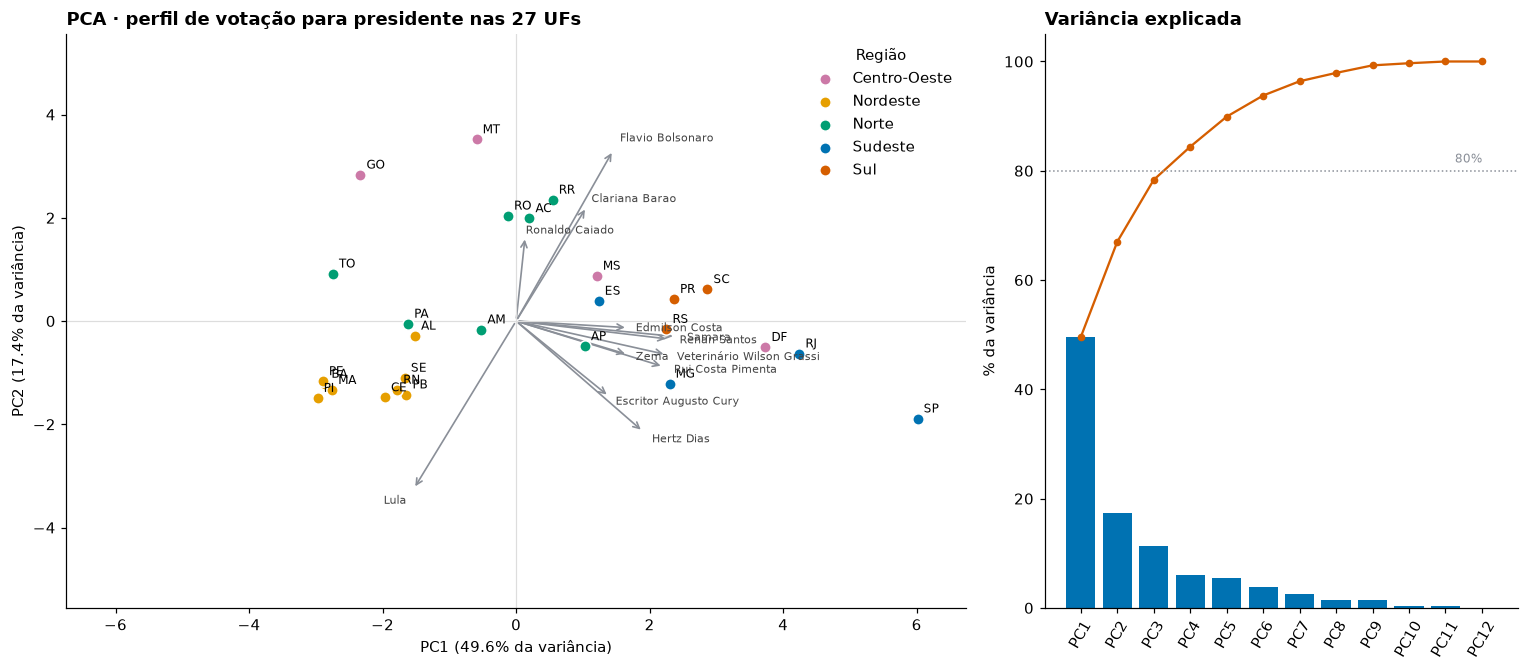

In [6]:
scores = pd.read_csv(PROC / "pca_scores_ufs.csv", index_col=0)
loadings = pd.read_csv(PROC / "pca_loadings.csv", index_col=0)
var = pd.read_csv(PROC / "pca_variancia.csv")

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1.9, 1]})

# --- (a) PC1 x PC2: UFs (pontos) + candidatos (setas = loadings) ---
for reg, g in scores.groupby("regiao"):
    ax.scatter(g["PC1"], g["PC2"], s=55, color=COR_REGIAO[reg], label=reg, zorder=3, edgecolor="white")
for uf, r in scores.iterrows():
    ax.annotate(uf, (r["PC1"], r["PC2"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
esc = 0.55 * np.abs(scores[["PC1", "PC2"]].values).max() / np.abs(loadings[["PC1", "PC2"]].values).max()
for cand, r in loadings.iterrows():
    ax.annotate("", xy=(r["PC1"] * esc, r["PC2"] * esc), xytext=(0, 0),
                arrowprops={"arrowstyle": "->", "color": CINZA, "lw": 1.1}, zorder=2)
    ax.text(r["PC1"] * esc * 1.07, r["PC2"] * esc * 1.07, cand.title(), fontsize=7.5, color="#444",
            ha="left" if r["PC1"] >= 0 else "right", va="center")
# limites explícitos: setas e rótulos dos candidatos também precisam caber (annotate/text não reescalam)
ponta = loadings[["PC1", "PC2"]].values * esc * 1.5
mx, my = np.abs(np.vstack([scores[["PC1", "PC2"]].values, ponta])).max(axis=0) * 1.12
ax.set_xlim(-mx, mx); ax.set_ylim(-my, my)
ax.axhline(0, color="#ddd", lw=.8); ax.axvline(0, color="#ddd", lw=.8)
ax.set_xlabel(f"PC1 ({var['variancia_explicada_%'].iloc[0]:.1f}% da variância)")
ax.set_ylabel(f"PC2 ({var['variancia_explicada_%'].iloc[1]:.1f}% da variância)")
ax.set_title("PCA · perfil de votação para presidente nas 27 UFs", loc="left")
ax.legend(title="Região", frameon=False, loc="best")

# --- (b) variância explicada por componente + acumulada ---
ax2.bar(var["componente"], var["variancia_explicada_%"], color=AZUL)
ax2.plot(var["componente"], var["acumulada_%"], color=LARANJA, marker="o", ms=4)
ax2.axhline(80, color=CINZA, ls=":", lw=1); ax2.text(len(var) - 1, 81.5, "80%", ha="right", fontsize=8, color=CINZA)
ax2.set_ylabel("% da variância"); ax2.set_title("Variância explicada", loc="left")
ax2.tick_params(axis="x", labelrotation=60)
fig.tight_layout(); fig.savefig(FIG / "pca_pc1_pc2.png"); plt.show()

A leitura dos loadings está em `reports/leitura_loadings_pca.md` e no `02_Analise.ipynb`.

## 5. Complementar — correlação de Spearman entre candidatos a presidente

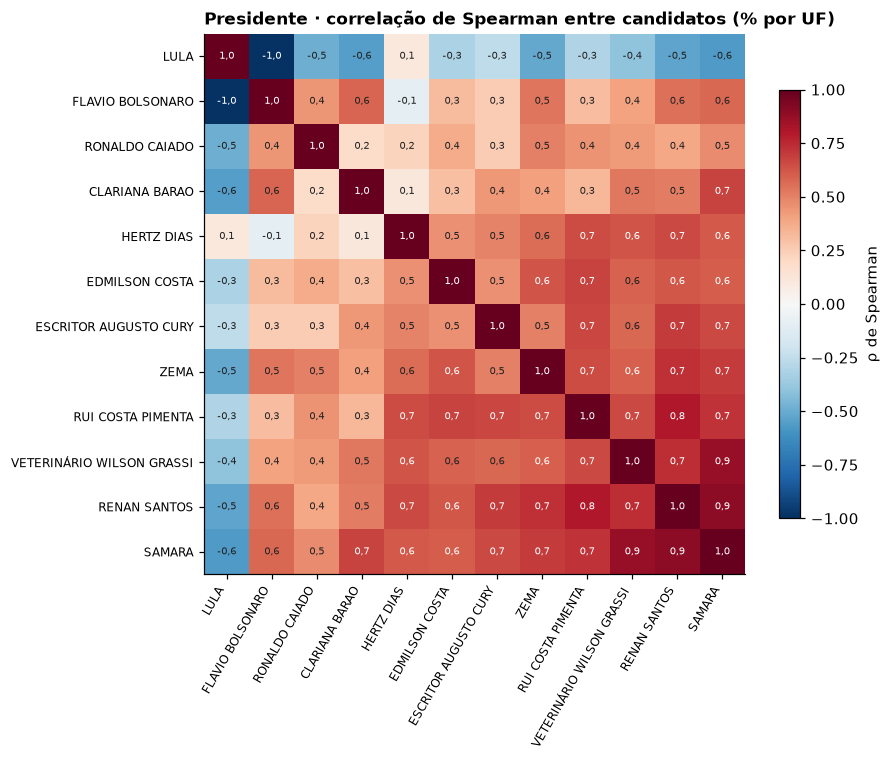

In [7]:
spear = pd.read_csv(PROC / "analise_spearman_presidente.csv", index_col=0)
fig, ax = plt.subplots(figsize=(8.2, 7))
ordem = spear.mean().sort_values().index                                        # ordena para destacar blocos
im = ax.imshow(spear.loc[ordem, ordem], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ordem)), ordem, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(ordem)), ordem, fontsize=8)
for i in range(len(ordem)):
    for j in range(len(ordem)):
        v = spear.loc[ordem[i], ordem[j]]
        ax.text(j, i, f"{v:.1f}".replace(".", ","), ha="center", va="center", fontsize=6.5,
                color="white" if abs(v) > .6 else "#222")
fig.colorbar(im, ax=ax, shrink=.75, label="ρ de Spearman")
ax.set_title("Presidente · correlação de Spearman entre candidatos (% por UF)", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "spearman_presidente_heatmap.png"); plt.show()